# MGS 3101 - Group Project: Business Analysis with Linear and Logistic Regression

**Team name:** ______________________  **Due date:** ______________________  **GitHub repo URL:** ______________________

**Dataset track chosen:** ______________________

| Member | Role | GitHub username |
|---|---|---|
| | Data Lead (Parts 1-2) | |
| | Linear Regression Lead (Part 3) | |
| | Logistic Regression Lead (Part 4) | |
| | Business Lead (Parts 5-6) | |

(Teams of 3 may combine two roles. Teams of 5 may add a Reviewer / Git Manager.)

## Overview

Your team plays a business analytics group for a fictional company. You will analyze **one** of the five datasets below with **both** methods you learned:

1. **Linear regression (Assignment 4):** predict a **numeric** business outcome.
2. **Logistic regression (Assignment 5):** predict a **yes/no** business outcome.

Then you will combine both into one practical recommendation: **which customers or deals should the team prioritize, and how much value is at stake?** All data are synthetic, so results do not describe any real company.

## Choose your dataset track

Pick **one** track (your instructor may assign it). The same notebook code works for every track: you only change the `TRACK` setting in Part 1.

| `TRACK` | Files needed (copy into your repo) | Row = | Numeric outcome (linear) | Yes/no outcome (logistic) | Business question |
|---|---|---|---|---|---|
| `saas_renewal` | `SaaS_Renewal_Opportunities_2025.csv`, `SaaS_Renewal_Accounts_2025.csv` (or the `SaaS_Renewal_Group_B_...` versions, set `VARIANT = 'B'`) | A contract renewal | Customer health score | Churned (did not renew) | Which expiring contracts should retention contact first? |
| `account_growth` | `Account_Growth_Accounts_2025.csv`, `Account_Growth_Cross_Sell_Outcomes_2025.csv`, `Account_Growth_Current_Holdings_2025.csv` | A customer account | Customer health score | Bought a cross-sell product | Which accounts should sales approach for cross-sell? |
| `nonprofit` | `Nonprofit_Campaign_Project_Members_2025.csv` (or `Nonprofit_Seasonal_Campaign_Members_2025.csv`, set `VARIANT = 'seasonal'`) | A person contacted in a campaign | Donation amount (donors only) | Donated | Whom should the next fundraising campaign contact? |
| `sales_activity` | `Sales_Activity_Project_Opportunities_2025.csv`, `Sales_Activity_Project_Accounts_2025.csv`, `Sales_Activity_Project_Activities_2025.csv` | A closed sales opportunity | Opportunity amount | Won the deal | Which deals deserve the most sales effort? |
| `sales_pipeline` | `Sales_Pipeline_Health_Snapshot_2025.csv` | A closed opportunity (won or lost) | Days from creation to close | Won the deal | What separates won deals from lost deals? |

Notes on the variants: the `seasonal` nonprofit file has the same people and results as the campaign file (it just has fewer columns), and `SaaS_Renewal_Group_B` has the same customer features as the original with different renewal outcomes and contract values, so the numeric (linear) results match while the churn results differ. Pick one variant per team.

Read the matching data guide (`.md` file) for field definitions before you start.

## Project parts

| Part | Task | Owner |
|---|---|---|
| 0 | Team GitHub setup | Everyone |
| 1 | Load and check the data | Data Lead |
| 2 | Explore the data | Data Lead |
| 3 | Linear regression: predict the numeric outcome | Linear Lead |
| 4 | Logistic regression: predict the yes/no outcome | Logistic Lead |
| 5 | Combine the models: who do we prioritize? | Business Lead |
| 6 | Stability check, recommendation, limitations | Business Lead (all review) |
| 7 | Final integration and submission | Everyone |

**A weak result is a valid result.** Some tracks have little predictive signal. If a model barely beats its baseline, say so, explain why, and make an honest recommendation. Do not hide it or tune the notebook until it looks good.

## Part 0: Team GitHub setup (everyone)

**One teammate (the Git Manager) does steps 1-3. Everyone else does steps 4-5.**

1. Create a **Private** repo named `mgs3101-group-project` with a README. Under **Settings > Collaborators**, add every teammate and your instructor.
2. Clone it, copy in this notebook and your track's CSV files, then publish them to `main`:

```
git clone https://github.com/OWNER/mgs3101-group-project.git
cd mgs3101-group-project
git add .
git commit -m "Add project notebook and data"
git push origin main
```

3. Add a `CONTRIBUTIONS.md` file (see Part 7) and push it.
4. Every other teammate clones the repo (`git clone ...`).
5. Each teammate creates a branch for their role:

```
git checkout -b part1-data        # or part3-linear, part4-logistic, part5-business
```

### Team workflow rules (to avoid merge conflicts)

- **Only edit the cells in your own part.** Do not reformat or re-run-and-save other people's cells.
- Commit small and often, with clear messages (for example `Part 3: fit linear model and metrics`). Each member needs **at least 3 meaningful commits**.
- To share your work, push your branch and open a **Pull Request** into `main`. **A teammate must review and approve** before you merge.
- Merge pull requests **one at a time**. After each merge, everyone updates their branch:

```
git checkout main
git pull origin main
git checkout your-branch
git merge main
```

- Notebook files can conflict. If Git reports a conflict, ask the teammate who last edited that section, or resolve it together on a call.
- Later parts depend on earlier cells (the data and the settings are created in Part 1). Merge Part 1 first so later parts can run.

Install packages if needed (run in a notebook cell, then restart the kernel): `%pip install numpy pandas matplotlib scikit-learn`

## Part 1: Load and check the data (Data Lead)

Branch: `part1-data`. Set your track in the first cell, then run the cells and answer the questions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from typing import Any

plt.style.use('seaborn-v0_8-whitegrid')

# ---- TEAM SETTINGS: set TRACK once, then leave these alone ----
TRACK = 'account_growth'   # 'saas_renewal' | 'account_growth' | 'nonprofit' | 'sales_activity' | 'sales_pipeline'
VARIANT = None           # saas_renewal: None or 'B'.  nonprofit: None or 'seasonal'.  Others: None.

# Keep these for your main results. Only change them in Part 6, then restore them.
TEST_SIZE = 0.25
SEED = 17
CONTACT_SHARE = 0.20     # the team can only act on 20% of customers (used in Parts 4-5)

print(f'Track: {TRACK}   Variant: {VARIANT}')

Track: account_growth   Variant: None


In [3]:
def load_track(track, variant=None):
    # Returns the modeling table plus the settings every later part uses.
    if track == 'saas_renewal':
        prefix = 'SaaS_Renewal_Group_B' if variant == 'B' else 'SaaS_Renewal'
        renewals = pd.read_csv(f'{prefix}_Opportunities_2025.csv')
        accounts = pd.read_csv(f'{prefix}_Accounts_2025.csv')
        data = renewals.merge(accounts, on='Account_ID', how='left', validate='one_to_one')
        data['Value_Weight_USD'] = data['Expiring_Total_Annual_Value_USD']
        data['Realized_Value_USD'] = data['Expiring_Total_Annual_Value_USD'] * data['Churned']
        return dict(
            title='SaaS renewal: customer health and churn risk', data=data, id_col='Renewal_ID',
            num_data=data, num_target='Customer_Health_Score', num_unit='health-score points',
            lin_features=['Product_Adoption_Percent', 'Support_Cases_Last_90_Days', 'Late_Invoices_Last_12_Months'],
            bin_target='Churned', event='churned (did not renew)', value_note='expiring contract value (USD)',
            log_features=['Customer_Tenure_Months', 'Product_Adoption_Percent',
                          'Support_Cases_Last_90_Days', 'Late_Invoices_Last_12_Months'],
            explore_cats=['Industry', 'Company_Size'], explore_x='Product_Adoption_Percent',
            segment_col='Company_Size')

    if track == 'account_growth':
        accounts = pd.read_csv('Account_Growth_Accounts_2025.csv')
        outcomes = pd.read_csv('Account_Growth_Cross_Sell_Outcomes_2025.csv')
        holdings = pd.read_csv('Account_Growth_Current_Holdings_2025.csv')
        held = holdings.groupby('Account_ID').agg(
            Products_Held=('SKU', 'nunique'),
            Holdings_Thousands_USD=('Annual_Contract_Value_USD', lambda s: s.sum() / 1000),
        ).reset_index()
        data = (accounts.merge(outcomes, on='Account_ID', how='left', validate='one_to_one')
                        .merge(held, on='Account_ID', how='left', validate='one_to_one'))
        avg_new = data.loc[data['Cross_Sell_Purchased'] == 1, 'New_Annual_Contract_Value_USD'].mean()
        data['Value_Weight_USD'] = avg_new   # new value is unknown beforehand: use the typical cross-sell value
        data['Realized_Value_USD'] = data['New_Annual_Contract_Value_USD']
        return dict(
            title='Account growth: customer health and cross-sell', data=data, id_col='Account_ID',
            num_data=data, num_target='Customer_Health_Score', num_unit='health-score points',
            lin_features=['Product_Adoption_Percent', 'Open_Support_Cases', 'Customer_Tenure_Months'],
            bin_target='Cross_Sell_Purchased', event='bought a cross-sell product',
            value_note='new annual contract value (USD) when a purchase happens',
            log_features=['Customer_Tenure_Months', 'Product_Adoption_Percent', 'Open_Support_Cases',
                          'Customer_Health_Score', 'Products_Held', 'Holdings_Thousands_USD', 'Company_Size', 'Industry'],
            explore_cats=['Industry', 'Company_Size'], explore_x='Product_Adoption_Percent',
            segment_col='Company_Size')

    if track == 'nonprofit':
        name = 'Nonprofit_Seasonal_Campaign_Members_2025.csv' if variant == 'seasonal' else 'Nonprofit_Campaign_Project_Members_2025.csv'
        data = pd.read_csv(name)
        # Months_Since_Last_Donation is blank for people with no prior donations
        data['Has_Prior_Donation'] = data['Months_Since_Last_Donation'].notna().astype(int)
        data['Months_Since_Last_Donation'] = data['Months_Since_Last_Donation'].fillna(0)
        data['Prior_Total_Donations_Hundreds_USD'] = data['Prior_Total_Donations_USD'] / 100
        data['Donation_Amount_USD'] = data['Donation_Amount_USD'].fillna(0)
        data['Value_Weight_USD'] = data.loc[data['Donated'] == 1, 'Donation_Amount_USD'].mean()
        data['Realized_Value_USD'] = data['Donation_Amount_USD']
        base = ['Donor_Tenure_Months', 'Prior_Donations_Count', 'Prior_Total_Donations_Hundreds_USD',
                'Months_Since_Last_Donation', 'Has_Prior_Donation']
        return dict(
            title='Nonprofit fundraising: donation size and response', data=data, id_col='Campaign_Member_ID',
            num_data=data[data['Donated'] == 1], num_target='Donation_Amount_USD', num_unit='US dollars per donation',
            lin_features=base, bin_target='Donated', event='donated',
            value_note='typical donation size (USD) when someone donates',
            log_features=base + ['Season', 'Campaign_Type'],
            explore_cats=['Season', 'Campaign_Type'], explore_x='Prior_Total_Donations_Hundreds_USD',
            segment_col='Season')

    if track == 'sales_activity':
        opps = pd.read_csv('Sales_Activity_Project_Opportunities_2025.csv')
        accts = pd.read_csv('Sales_Activity_Project_Accounts_2025.csv')
        acts = pd.read_csv('Sales_Activity_Project_Activities_2025.csv')
        # Only count activities up to the snapshot date so the model uses information available then
        a = acts.merge(opps[['Opportunity_ID', 'Snapshot_Date']], on='Opportunity_ID')
        a = a[a['Activity_Date'] <= a['Snapshot_Date']]
        counts = a.groupby('Opportunity_ID').size().rename('Activities_By_Snapshot').reset_index()
        data = (opps.merge(accts, on='Account_ID', how='left', validate='many_to_one')
                    .merge(counts, on='Opportunity_ID', how='left'))
        data['Activities_By_Snapshot'] = data['Activities_By_Snapshot'].fillna(0)
        data['Opportunity_Amount_Thousands_USD'] = data['Opportunity_Amount_USD'] / 1000
        data['Value_Weight_USD'] = data['Opportunity_Amount_USD']
        data['Realized_Value_USD'] = data['Opportunity_Amount_USD'] * data['Won']
        return dict(
            title='Sales activity: deal size and win probability', data=data, id_col='Opportunity_ID',
            num_data=data, num_target='Opportunity_Amount_USD', num_unit='US dollars',
            lin_features=['Company_Size', 'Offering_Type', 'Industry', 'Region', 'Lead_Source'],
            bin_target='Won', event='won', value_note='opportunity amount (USD)',
            log_features=['Opportunity_Amount_Thousands_USD', 'Activities_By_Snapshot', 'Lead_Source',
                          'Offering_Type', 'Industry', 'Company_Size', 'Region'],
            explore_cats=['Company_Size', 'Offering_Type'], explore_x='Activities_By_Snapshot',
            segment_col='Company_Size')

    if track == 'sales_pipeline':
        pipe = pd.read_csv('Sales_Pipeline_Health_Snapshot_2025.csv')
        data = pipe[pipe['Stage'].isin(['Closed Won', 'Closed Lost'])].copy()
        data['Won'] = (data['Stage'] == 'Closed Won').astype(int)
        data['Days_To_Close'] = (pd.to_datetime(data['Actual_Close_Date']) - pd.to_datetime(data['Created_Date'])).dt.days
        data['Amount_Thousands_USD'] = data['Amount_USD'] / 1000
        data['Value_Weight_USD'] = data['Amount_USD']
        data['Realized_Value_USD'] = data['Amount_USD'] * data['Won']
        data = data.reset_index(drop=True)
        return dict(
            title='Sales pipeline: closed deals', data=data, id_col='Opportunity_ID',
            num_data=data, num_target='Days_To_Close', num_unit='days',
            lin_features=['Completed_Activity_Count', 'Amount_Thousands_USD', 'Company_Size', 'Offering_Type'],
            bin_target='Won', event='won', value_note='opportunity amount (USD)',
            log_features=['Amount_Thousands_USD', 'Completed_Activity_Count', 'Decision_Maker_Status',
                          'Budget_Status', 'Lead_Source', 'Offering_Type', 'Opportunity_Type',
                          'Company_Size', 'Industry'],
            explore_cats=['Company_Size', 'Lead_Source'], explore_x='Completed_Activity_Count',
            segment_col='Company_Size')

    raise ValueError(f'Unknown TRACK: {track}')

cfg: dict[str, Any] = load_track(TRACK, VARIANT)
data: pd.DataFrame = cfg['data']
print(cfg['title'])
print(f'Rows in modeling table: {len(data):,}   Missing values in model columns: '
      f'{int(data[cfg["lin_features"] + cfg["log_features"] + [cfg["bin_target"]]].isna().sum().sum())}')
print(f'Share of rows that {cfg["event"]}: {data[cfg["bin_target"]].mean():.1%}')
print(f'Numeric outcome for linear regression: {cfg["num_target"]} ({cfg["num_unit"]}); '
      f'rows used: {len(cfg["num_data"]):,}')
data.head()

Account growth: customer health and cross-sell
Rows in modeling table: 5,000   Missing values in model columns: 0
Share of rows that bought a cross-sell product: 26.2%
Numeric outcome for linear regression: Customer_Health_Score (health-score points); rows used: 5,000


,Account_ID,Account_Name,Snapshot_Date,Industry,Region,Company_Size,Customer_Tenure_Months,Product_Adoption_Percent,Open_Support_Cases,Customer_Health_Score,Outcome_Window_End,Cross_Sell_Purchased,New_SKU,New_SKU_Quantity,Purchase_Date,New_Annual_Contract_Value_USD,Products_Held,Holdings_Thousands_USD,Value_Weight_USD,Realized_Value_USD
0,AG-ACCT-00001,Fictional Growth Company 00001,2025-06-30,Technology,South,Small,36,68.1,1,55,2025-12-31,1,PS-IMPLEMENT,1.0,2025-10-14,10000,5,49.2,22532.925898,10000
1,AG-ACCT-00002,Fictional Growth Company 00002,2025-06-30,Retail,Midwest,Midmarket,58,48.7,0,60,2025-12-31,0,NaN,NaN,NaN,0,4,108.0,22532.925898,0
2,AG-ACCT-00003,Fictional Growth Company 00003,2025-06-30,Healthcare,Northeast,Enterprise,42,35.1,1,60,2025-12-31,0,NaN,NaN,NaN,0,1,12.0,22532.925898,0
3,AG-ACCT-00004,Fictional Growth Company 00004,2025-06-30,Education,Midwest,Small,115,46.5,1,64,2025-12-31,0,NaN,NaN,NaN,0,3,35.6,22532.925898,0
4,AG-ACCT-00005,Fictional Growth Company 00005,2025-06-30,Education,Northeast,Small,38,80.3,0,81,2025-12-31,0,NaN,NaN,NaN,0,4,37.2,22532.925898,0


In [4]:
numeric_cols = list(dict.fromkeys(
    [c for c in cfg['lin_features'] + cfg['log_features'] + [cfg['num_target']]
     if pd.api.types.is_numeric_dtype(data[c])]
))
data[numeric_cols].describe().round(1)

,Product_Adoption_Percent,Open_Support_Cases,Customer_Tenure_Months,Customer_Health_Score,Products_Held,Holdings_Thousands_USD
count,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
mean,66.9,1.0,62.9,67.1,3.5,74.2
std,17.9,1.3,33.4,14.4,1.7,61.5
min,5.6,0.0,6.0,13.0,1.0,3.6
25%,54.7,0.0,34.0,58.0,2.0,30.0
50%,69.2,0.0,63.0,68.0,3.0,57.3
75%,80.8,1.0,92.0,77.0,5.0,101.8
max,99.7,12.0,120.0,100.0,6.0,492.8


In [5]:
accounts_check = pd.read_csv('Account_Growth_Accounts_2025.csv')

print('Original accounts:', len(accounts_check))
print('Rows after joining:', len(data))
print('Duplicate Account_IDs:', data['Account_ID'].duplicated().sum())
print('Original accounts missing after joining:',
      (~accounts_check['Account_ID'].isin(data['Account_ID'])).sum())

Original accounts: 5000
Rows after joining: 5000
Duplicate Account_IDs: 0
Original accounts missing after joining: 0


**Answer 1 (Data Lead):**
- What does one row represent? What are the numeric outcome and the yes/no outcome, and what are their units or meaning?
- What share of rows have the yes/no event? Why does that share matter when judging a model?
- Did your files join without losing or duplicating rows? Are there missing values, and how were they handled? (The code in `load_track` fills or flags some; read it and explain what it does.)
- Which predictors might be *derived from* or *measured at the same time as* an outcome, so that a strong fit could be misleading? (For example, a health score built from the same inputs, or an activity count measured through the close date.)

*answer:* Each row represents one existing customer account. The numeric outcome is Customer_Health_Score, measured in health-score points. The yes/no outcome is Cross_Sell_Purchased: 1 means the customer bought an additional SKU during July–December 2025 that it did not hold at the June 30 snapshot, while 0 means no such purchase was recorded.

About 26.2% of customers purchased a cross-sell product. A model that always predicts “no purchase” would therefore be about 73.8% accurate in this dataset, but it would miss every buyer. This means accuracy alone is not enough to judge the model; precision and recall also matter.

The original accounts file and the joined table both contain 5,000 rows, with no duplicate Account_IDs or original customers lost. The code first aggregates holdings by Account_ID, then uses left joins with one-to-one validation to keep one row per customer. There are no missing values in the model columns, so no filling was needed. Nonbuyers have blank purchase details, such as New_SKU and Purchase_Date. These blanks are left unchanged because no purchase occurred, and these fields are not predictors.

The data guide states that Customer_Health_Score is partly derived from Product_Adoption_Percent and Open_Support_Cases. A strong fit may therefore reflect how the score was constructed, rather than an ability to predict future customer health. It does not prove causation. Later purchase details must also be excluded from the purchase predictors because they were not known at the June 30 snapshot.

**Git checkpoint:** commit on `part1-data`, push, and open a pull request.

## Part 2: Explore the data (Data Lead)

Look for patterns before modeling.

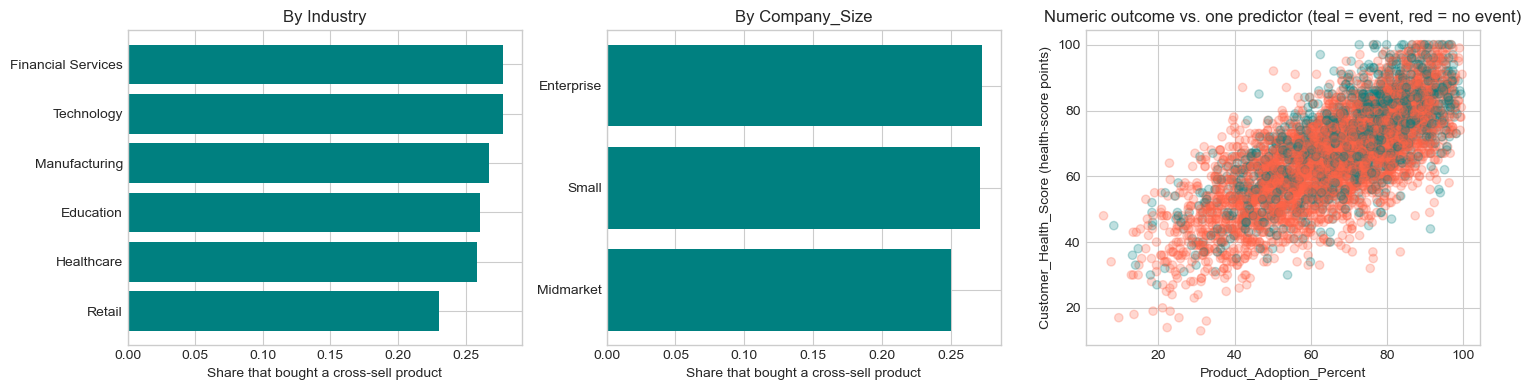

In [6]:
cats = cfg['explore_cats']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes[:2], cats):
    rate = data.groupby(col)[cfg['bin_target']].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.to_numpy(), color='teal')
    ax.set_xlabel(f'Share that {cfg["event"]}')
    ax.set_title(f'By {col}')

nd = cfg['num_data']
colors = nd[cfg['bin_target']].map({0: 'tomato', 1: 'teal'}) if nd[cfg['bin_target']].nunique() > 1 else 'teal'
axes[2].scatter(nd[cfg['explore_x']], nd[cfg['num_target']], c=colors, alpha=0.25)
axes[2].set_xlabel(cfg['explore_x'])
axes[2].set_ylabel(f'{cfg["num_target"]} ({cfg["num_unit"]})')
axes[2].set_title('Numeric outcome vs. one predictor (teal = event, red = no event)')

plt.tight_layout()
plt.show()

In [7]:
corr_cols = list(dict.fromkeys(numeric_cols + [cfg['bin_target']]))
data[corr_cols].corr().round(2)

,Product_Adoption_Percent,Open_Support_Cases,Customer_Tenure_Months,Customer_Health_Score,Products_Held,Holdings_Thousands_USD,Cross_Sell_Purchased
Product_Adoption_Percent,1.00,0.01,-0.00,0.73,-0.01,-0.00,0.10
Open_Support_Cases,0.01,1.00,-0.01,-0.27,0.00,-0.00,-0.04
Customer_Tenure_Months,-0.00,-0.01,1.00,0.01,-0.00,0.00,0.08
Customer_Health_Score,0.73,-0.27,0.01,1.00,0.01,0.01,0.15
Products_Held,-0.01,0.00,-0.00,0.01,1.00,0.61,0.02
Holdings_Thousands_USD,-0.00,-0.00,0.00,0.01,0.61,1.00,0.01
Cross_Sell_Purchased,0.10,-0.04,0.08,0.15,0.02,0.01,1.00


**Answer 2 (Data Lead):** Describe at least three patterns you see (for example, which segments have a higher event rate, how a predictor relates to the numeric outcome, which variables correlate most with the yes/no outcome). Which variables look most promising for each model? Does a straight line look reasonable for the numeric outcome?

*Your answer here:* Cross-sell rates are about 28% in Financial Services and Technology, compared with about 23% in Retail, a difference of about five percentage points. Rates by company size range from about 25% to 27%, a smaller difference of about two percentage points. Industry therefore looks worth testing as a predictor in the logistic model, while company size shows a smaller difference in observed purchase rates.

Customer health is positively correlated with product adoption (r = 0.73) and negatively correlated with open support cases (r = −0.27). Tenure has almost no linear relationship with health (r = 0.01). Adoption and open support cases look most promising for the linear model. The scatterplot shows a roughly linear upward trend, so a straight line seems reasonable as a starting point, although there is still variation around the trend. The strong relationship also needs caution because the health score is partly based on adoption and support cases.

Customer health has the strongest correlation with cross-sell purchase among the numeric predictors, but it is weak (r = 0.15). Adoption (r = 0.10) and tenure (r = 0.08) have weaker positive correlations, while support cases have a small negative correlation (r = −0.04). Health, adoption, and tenure look worth testing in the logistic model, but test-set results are needed to judge their predictive usefulness. These observed relationships do not establish causation.

**Git checkpoint:** commit, push, request a teammate's review, and merge `part1-data` into `main` before the other parts begin.

## Part 3: Linear regression - predict the numeric outcome (Linear Lead)

Branch: `part3-linear`. Update from `main` first. Compare a **baseline** (training-set average) to a **linear regression**. Text predictors are converted to 0/1 indicator columns; each indicator's slope is the difference from the left-out category.

Report test-set **MAE** and **RMSE** in the outcome's units. Lower is better.

In [8]:
lin_data = cfg['num_data']
X_lin = pd.get_dummies(lin_data[cfg['lin_features']], drop_first=True).astype(float)
y_lin = lin_data[cfg['num_target']]

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_lin, y_lin, test_size=TEST_SIZE, random_state=SEED
)
print(f'Training observations: {len(Xl_train)}   Test observations: {len(Xl_test)}')

lin_baseline = DummyRegressor(strategy='mean').fit(Xl_train, yl_train)
lin_model = LinearRegression().fit(Xl_train, yl_train)
lin_baseline_pred = lin_baseline.predict(Xl_test)
lin_pred = lin_model.predict(Xl_test)

lin_results = pd.DataFrame({
    'model': ['Training-mean baseline', 'Linear regression'],
    'test_MAE': [mean_absolute_error(yl_test, lin_baseline_pred), mean_absolute_error(yl_test, lin_pred)],
    'test_RMSE': [np.sqrt(mean_squared_error(yl_test, lin_baseline_pred)),
                  np.sqrt(mean_squared_error(yl_test, lin_pred))],
    'test_R2': [r2_score(yl_test, lin_baseline_pred), r2_score(yl_test, lin_pred)],
})
print(f'Outcome: {cfg["num_target"]} ({cfg["num_unit"]}).  MAE and RMSE are in those units.')
print(f'Baseline predicts the training mean: {yl_train.mean():.2f}')
lin_results.round(2)

Training observations: 3750   Test observations: 1250
Outcome: Customer_Health_Score (health-score points).  MAE and RMSE are in those units.
Baseline predicts the training mean: 67.04


,model,test_MAE,test_RMSE,test_R2
0,Training-mean baseline,11.62,14.68,-0.00
1,Linear regression,7.26,9.08,0.62


In [9]:
slopes = pd.DataFrame({'predictor': X_lin.columns, 'slope': lin_model.coef_})
slopes['slope'] = slopes['slope'].round(3)
print(f'Intercept: {lin_model.intercept_:.2f} ({cfg["num_unit"]})')
slopes

Intercept: 30.24 (health-score points)


,predictor,slope
0,Product_Adoption_Percent,0.592
1,Open_Support_Cases,-3.006
2,Customer_Tenure_Months,0.004


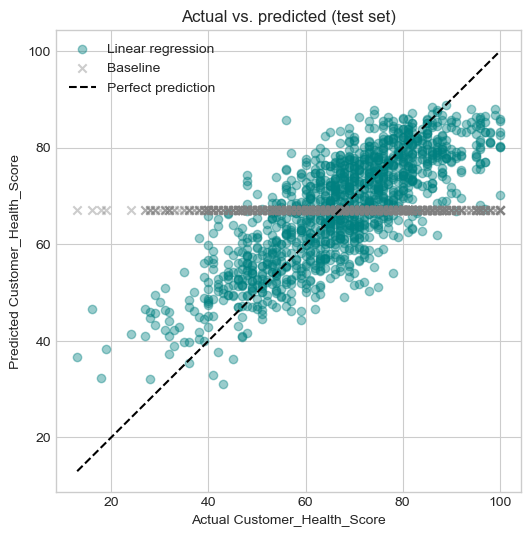

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(yl_test, lin_pred, alpha=0.4, color='teal', label='Linear regression')
plt.scatter(yl_test, lin_baseline_pred, alpha=0.4, color='gray', marker='x', label='Baseline')
low, high = yl_test.min(), yl_test.max()
plt.plot([low, high], [low, high], 'k--', label='Perfect prediction')
plt.xlabel(f'Actual {cfg["num_target"]}')
plt.ylabel(f'Predicted {cfg["num_target"]}')
plt.title('Actual vs. predicted (test set)')
plt.legend()
plt.show()

**Answer 3 (Linear Lead):**
- Report the training and test counts, and the test MAE and RMSE for both models. Which is better, and is the difference large enough to matter to the business?
- Interpret **at least two slopes** in context with units (for example: "holding the other predictors constant, one more unit of X is associated with a change of ___ in the outcome"). For an indicator column, the slope compares that category with the left-out category.
- What does the baseline predict, and why is it a useful comparison? What does R-squared tell you here?
- Does a strong fit prove that changing a predictor would change the outcome? Why or why not?

*Your answer here:* The training set contains 3,750 customers, and the test set contains 1,250. The baseline predicts the training-set average health score of 67.04 for every customer. It provides a simple comparison to check whether customer characteristics improve predictions. Its test MAE is 11.62 points and RMSE is 14.68 points, compared with 7.26 and 9.08 points for linear regression. The regression model performs better, reducing MAE by 4.36 points, or about 37.5% relative to the baseline. This improvement could be useful for estimating customer health, but the remaining error means managers should be careful when making decisions based on small differences in predicted scores.

Holding support cases and tenure constant, each one-percentage-point increase in product adoption is associated with a 0.592-point increase in predicted customer health. Holding adoption and tenure constant, each additional open support case is associated with a 3.006-point decrease in predicted health.

The regression model’s test R-squared is 0.62. This means its squared prediction error is about 62% lower than predicting the test-set mean for every customer. It does not mean that 62% of predictions are correct. MAE and RMSE describe the size of the prediction errors in health-score points.

A strong fit does not prove that changing a predictor would cause the outcome to change. The model shows associations, and the data guide states that the health score is partly constructed from adoption and support cases. Some of the fit therefore reflects how the score was created, rather than independent evidence that changing these inputs would improve actual customer health.

**Git checkpoint:** commit at least twice (model, then written answers), push, and open a pull request for review.

## Part 4: Logistic regression - predict the yes/no outcome (Logistic Lead)

Branch: `part4-logistic`. Update from `main` first. Predict whether the event happens (1) or not (0). The baseline always predicts the most common outcome.

When the event is uncommon, accuracy alone can mislead. Focus on **recall** (share of real events found), **precision** (share of flagged rows that really have the event), and **ROC AUC** (how well the model ranks events above non-events; 0.5 = guessing).

The usual 0.5 cutoff may flag very few rows. So the table also shows a **top-20% cutoff** that flags the 20% of rows with the highest predicted probability (the share your team can act on).

In [ ]:
X_log = pd.get_dummies(data[cfg['log_features']], drop_first=True).astype(float)
y_log = data[cfg['bin_target']]

idx_train, idx_test = train_test_split(
    data.index, test_size=TEST_SIZE, random_state=SEED, stratify=y_log
)
Xg_train, Xg_test = X_log.loc[idx_train], X_log.loc[idx_test]
yg_train, yg_test = y_log.loc[idx_train], y_log.loc[idx_test]
print(f'Training observations: {len(Xg_train)}   Test observations: {len(Xg_test)}')
print(f'Event rate - train: {yg_train.mean():.1%}   test: {yg_test.mean():.1%}')

log_baseline = DummyClassifier(strategy='most_frequent').fit(Xg_train, yg_train)
log_model = LogisticRegression(max_iter=5000).fit(Xg_train, yg_train)

event_prob = log_model.predict_proba(Xg_test)[:, 1]
pred_050 = (event_prob >= 0.5).astype(int)
cutoff_top = np.quantile(event_prob, 1 - CONTACT_SHARE)
pred_top = (event_prob >= cutoff_top).astype(int)
pred_base = log_baseline.predict(Xg_test)

def score(y_true, y_pred, y_score):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0),
        roc_auc_score(y_true, y_score),
    ]

log_results = pd.DataFrame(
    [
        score(yg_test, pred_base, np.zeros(len(yg_test))),
        score(yg_test, pred_050, event_prob),
        score(yg_test, pred_top, event_prob),
    ],
    index=['Most-frequent baseline', 'Logistic regression (0.5 cutoff)',
           f'Logistic regression (top {CONTACT_SHARE:.0%} flagged)'],
    columns=['accuracy', 'precision', 'recall', 'F1', 'ROC_AUC'],
)
log_results.round(3)

In [ ]:
odds = pd.DataFrame({
    'predictor': X_log.columns,
    'coefficient_log_odds': log_model.coef_[0],
    'odds_ratio_per_unit': np.exp(log_model.coef_[0]),
})
display(odds.round(3))

for label, pred in [('0.5 cutoff', pred_050), (f'top {CONTACT_SHARE:.0%} flagged', pred_top)]:
    print(f'Confusion matrix ({label}, test set):')
    display(pd.DataFrame(
        confusion_matrix(yg_test, pred),
        index=['Actual: no event', 'Actual: event'],
        columns=['Predicted: no event', 'Predicted: event'],
    ))

In [ ]:
# Precision / recall trade-off: flag the top share of rows by predicted probability.
rows = []
base_rate = yg_test.mean()
for share in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    cut = np.quantile(event_prob, 1 - share)
    pred = (event_prob >= cut).astype(int)
    prec = precision_score(yg_test, pred, zero_division=0)
    rows.append({
        'share_flagged': share,
        'rows_flagged': int(pred.sum()),
        'precision': prec,
        'recall': recall_score(yg_test, pred, zero_division=0),
        'lift_vs_random': prec / base_rate,
    })
pd.DataFrame(rows).round(3)

**Answer 4 (Logistic Lead):**
- Report training/test counts and the test accuracy, recall, and ROC AUC for the baseline and the logistic model. Which is better? Why can the baseline's accuracy be misleading here?
- Interpret **at least two odds ratios** in context (for example: "holding the others constant, each additional unit of X multiplies the odds of the event by ___"; values below 1 lower the odds).
- Using the confusion matrices, how many real events did the model miss, and how many non-events did it flag by mistake?
- Using the trade-off table, which share of rows would you flag if acting on a flagged row costs money but a missed event costs far more (or the reverse)? Explain, and report the lift.

*Your answer here:*

**Git checkpoint:** commit at least twice, push, and open a pull request for review.

## Part 5: Combine the models - who do we prioritize? (Business Lead)

Branch: `part5-business`. Update from `main` after Parts 3 and 4 are merged.

Use the predicted event probabilities from Part 4 and the value at stake to rank the test-set rows by **expected value** (predicted probability x value weight). Then compare against picking rows at random, and break the results down by segment.

Assume the team can only act on `CONTACT_SHARE` (20%) of rows.

In [ ]:
action = data.loc[idx_test, [
    cfg['id_col'], cfg['segment_col'], cfg['bin_target'], 'Value_Weight_USD', 'Realized_Value_USD',
]].copy()
action['event_probability'] = event_prob
action['expected_value_USD'] = action['event_probability'] * action['Value_Weight_USD']

n_act = int(len(action) * CONTACT_SHARE)
ranked = action.sort_values('expected_value_USD', ascending=False)
top = ranked.head(n_act)

total_value = action['Realized_Value_USD'].sum()
value_model = top['Realized_Value_USD'].sum()
value_random = total_value * CONTACT_SHARE   # expected value from random selection

print(f'Rows in test set: {len(action)}   Rows prioritized ({CONTACT_SHARE:.0%}): {n_act}')
print(f'Value at stake (what the weight represents: {cfg["value_note"]}): ${total_value:,.0f}')
print(f'Value reached by the ranked list: ${value_model:,.0f} ({value_model / total_value:.1%})')
print(f'Value reached by random selection (expected): ${value_random:,.0f} ({CONTACT_SHARE:.1%})')
print(f'Events reached by the ranked list: {int(top[cfg["bin_target"]].sum())} of {int(action[cfg["bin_target"]].sum())}')

top.head(10).round(2)

In [ ]:
# Cumulative gains: how much value do we reach as we act on more rows?
gain = ranked['Realized_Value_USD'].cumsum() / total_value
share_acted = np.arange(1, len(ranked) + 1) / len(ranked)

plt.figure(figsize=(7, 5))
plt.plot(share_acted, gain.to_numpy(), color='teal', label='Ranked by expected value')
plt.plot([0, 1], [0, 1], 'k--', label='Random selection')
plt.axvline(CONTACT_SHARE, color='tomato', linestyle=':', label=f'{CONTACT_SHARE:.0%} acted on')
plt.xlabel('Share of rows acted on')
plt.ylabel('Share of total value reached')
plt.title('Cumulative gains (test set)')
plt.legend()
plt.show()

In [ ]:
seg = cfg['segment_col']
summary = action.assign(prioritized=action[cfg['id_col']].isin(top[cfg['id_col']]).astype(int))
summary.groupby(seg).agg(
    rows=(cfg['id_col'], 'count'),
    actual_event_rate=(cfg['bin_target'], 'mean'),
    avg_predicted_probability=('event_probability', 'mean'),
    rows_prioritized=('prioritized', 'sum'),
    expected_value_USD=('expected_value_USD', 'sum'),
    realized_value_USD=('Realized_Value_USD', 'sum'),
).round(3)

**Answer 5 (Business Lead):**
- How much more value does the ranked list reach than random selection? Is that gain large enough to justify building and using the ranking?
- Why rank by expected value (probability x value) instead of probability alone? In your track, does the ranking differ from ranking by probability? Why or why not? (Hint: look at how `Value_Weight_USD` is defined for your track in `load_track`.)
- Do the segments behave differently? Where would you focus, and where would you avoid spending effort?
- Connect Parts 3 and 4: what does the numeric model tell the business that the yes/no model does not, and how would a manager use both together?
- Suggest one concrete action for the prioritized rows and one for the rest.

*Your answer here:*

**Git checkpoint:** commit at least twice, push, and open a pull request for review.

## Part 6: Stability check, recommendation, and limitations (Business Lead, whole team reviews)

### Stability check

**Do not write new code.** Change `TEST_SIZE` and `SEED` in the Part 1 settings cell, then **Restart and Run All**. Record the results each time.

- **Run A:** `TEST_SIZE = 0.20`, `SEED = 17`
- **Run B:** `TEST_SIZE = 0.25`, `SEED = 7`

Then **restore `TEST_SIZE = 0.25` and `SEED = 17`** and run all cells again so the saved notebook shows the original results.

| Run | Linear: baseline RMSE | Linear: model RMSE | Logistic: ROC AUC | Logistic: recall (top 20%) | % of value reached at 20% acted on |
|---|---|---|---|---|---|
| Original (0.25, seed 17) | | | | | |
| Run A (0.20, seed 17) | | | | | |
| Run B (0.25, seed 7) | | | | | |

**Answer 6a:** Did either model's conclusion change across runs? Did changing the test size or the random split matter more? What does this say about relying on a single test score?

*Your answer here:*

### Recommendation to leadership

**Answer 6b (about 200-250 words):** Write a short memo to the business leader for your track. State whether to adopt the numeric model, the yes/no model, both, or neither, and how to use them. Cite specific numbers from Parts 3-5 and Part 6a. Say what you would test next before a full rollout.

*Your memo here:*

### Limitations and ethics

**Answer 6c:** Describe at least **three** limitations. Consider: synthetic data; predictors that are derived from or measured at the same time as the outcome; a random split instead of predicting future records (earlier records for training, later ones for testing); other drivers not in the data; the cutoff choice; weak signal; and the fact that correlation does not prove that changing a predictor would change the outcome.

*Your answer here:*

**Answer 6d:** Name one risk of acting on these predictions with real people or customers (for example, treating low-ranked people worse, or people learning they were scored). How would your team reduce it?

*Your answer here:*

**Git checkpoint:** commit, push, and open a pull request. Another teammate must approve it.

## Part 7: Final integration and submission (everyone)

1. Make sure all pull requests are merged into `main`. Everyone runs `git checkout main` then `git pull origin main`.
2. **Restart the kernel and Run All** on `main` to confirm the notebook runs top to bottom without errors, with `TEST_SIZE = 0.25` and `SEED = 17`.
3. Fill in `CONTRIBUTIONS.md` with a table like the one below. Commit and push it.

```
| Member | GitHub username | Parts owned | Commits | PRs opened | PRs reviewed |
|---|---|---|---|---|---|
```

4. Create a **release tag** on `main` so your submission is frozen:

```
git tag -a v1.0 -m "Final submission"
git push origin v1.0
```

5. Submit the repository URL. Do not push changes after the deadline.

## Submission checklist

- [ ] Team table, dataset track, and repository URL filled in at the top
- [ ] Notebook runs top to bottom with all outputs, tables, and plots visible
- [ ] Answers 1-6 complete, using plain language, units, and numbers from your results
- [ ] Original settings (`TEST_SIZE = 0.25`, `SEED = 17`) restored after the stability check
- [ ] Each member has at least 3 commits, 1 pull request opened, and 1 pull request reviewed
- [ ] `CONTRIBUTIONS.md` is complete and the `v1.0` tag is pushed
- [ ] Repository includes the notebook and your track's CSV files

## Suggested grading

| Component | Points |
|---|---|
| Data preparation and exploration (Parts 1-2) | 15 |
| Linear regression and interpretation (Part 3) | 20 |
| Logistic regression and interpretation (Part 4) | 20 |
| Combined business analysis (Part 5) | 15 |
| Stability, recommendation, and limitations (Part 6) | 15 |
| GitHub collaboration (branches, PRs, reviews, commits, contributions) | 15 |
| **Total** | **100** |